In [ ]:
from os import chdir
from os.path import abspath
thepath = abspath("../base")
chdir(thepath)

In [2]:
# yaml processing file loading. 
import yaml
import numpy as np
import matplotlib.pyplot as plt
from os.path import exists, split, join, normpath, isdir

from stl import mesh
from LBC_centreline import LBC, return_LBC_centreline
from utils import array_to_o3d
from LBC_centreline import return_LBC_centreline


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [6]:
with open(f"./notebooks/conduit_map.yaml", "r") as f: 
    conduit_map = yaml.safe_load(f)
    f.close()

In [4]:
with open(f"./notebooks/plot_kwargs.yaml", "r") as f: 
    p = yaml.safe_load(f)
    f.close()

In [5]:
skeleton_kwargs = p["skeleton_kwargs"]
node_kwargs = p["node_kwargs"]
ct_kwargs = p["ct_kwargs"]
mesh_kwargs = p["mesh_kwargs"]
start_kwargs = p["start_kwargs"]
end_kwargs = p["end_kwargs"]

In [6]:
# set up the conduit name and ID. 
ID = 8
CONDUIT_NAME = conduit_map[ID]

In [7]:
## import the mesh data. 
mesh_fp =  f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}.stl"
data = mesh.Mesh.from_file(mesh_fp)


In [8]:
lbc_centreline_fp = join(f"../temp/{ID}_{CONDUIT_NAME}/lbc/", f"{CONDUIT_NAME}_centreline.txt")

pcd = data.centroids
# convert to open3d object-
pcd = array_to_o3d(pcd)

In [9]:
with open(f"../data/{ID}_{CONDUIT_NAME}/{CONDUIT_NAME}_processing.yaml", "r") as f: 
    process_p = yaml.safe_load(f)
    f.close()

In [10]:
# initialise the list containing the stages of contraction. 
skeleton_clouds = [] 
for max_it_step in range(1,6):
    # set up the Laplacian-based contraction algorithm 
    lbc = LBC(point_cloud=pcd, 
            down_sample=process_p["lbc"]["voxelSize"],
            init_attraction = process_p["lbc"]["initAttraction"], 
            init_contraction = process_p["lbc"]["initContraction"], 
            max_iteration_steps=max_it_step)
    lbc.extract_skeleton()
    skeleton_clouds.append(lbc.contracted_point_cloud)

2026-03-25 10:21:49,106 - PCD #points: 3824
Volume ratio: 1.0. Contraction weights: 171.66513525337317. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:00<00:00,  5.99it/s]2026-03-25 10:21:49,591 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 171.66513525337317. Attraction weights: 2.0. Progress LBC: 100%|██████████| 1/1 [00:00<00:00,  3.32it/s]
2026-03-25 10:21:49,625 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 343.33027050674633. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:00<00:00,  5.31it/s]2026-03-25 10:21:50,394 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 343.33027050674633. Attraction weights: 2.0. Progress LBC: 100%|██████████| 2/2 [00:00<00:00,  3.30it/s]
2026-03-25 10:21:50,458 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.030891912428677. Progress LBC: 100%|██████████| 3/3 [00:00<00:00,  4.64it/s]2026-03-25 10:21:51,570 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.030891912428677. Progress LBC: 100%|██████████| 3/3 [00:00<00:00,  3.16it/s]
2026-03-25 10:21:51,613 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.030891912428677. Progress LBC:  75%|███████▌  | 3/4 [00:00<00:00,  4.94it/s]2026-03-25 10:21:52,812 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.030891912428677. Progress LBC:  75%|███████▌  | 3/4 [00:01<00:00,  2.87it/s]
2026-03-25 10:21:52,878 - PCD #points: 3824


Contraction is Done.


Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.030891912428677. Progress LBC:  60%|██████    | 3/5 [00:00<00:00,  4.38it/s]2026-03-25 10:21:54,232 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.6605410134927. Attraction weights: 15.030891912428677. Progress LBC:  60%|██████    | 3/5 [00:01<00:00,  2.57it/s]

Contraction is Done.


In [11]:
# definition of processing metaparameters
lbc_args = dict(init_attraction = process_p["lbc"]["initAttraction"], 
                init_contraction = process_p["lbc"]["initContraction"],
                down_sample = process_p["lbc"]["voxelSize"])

ct_args = dict(keep = True, keep_centreline = False, centreline_down_sample = process_p["lbc"]["downSample"])

In [12]:
out_LBC = return_LBC_centreline(data,
                            ct_args= ct_args,
                            lbc_args= lbc_args)

LBC_ct = out_LBC["sparse_cloud"][np.array(out_LBC["centreline"]).astype(int)]
P1 = LBC_ct[0]
P2 = LBC_ct[-1]

read file in 0.0000s


2026-03-25 10:21:54,916 - PCD #points: 3824


contracted file in 0.6197s


Volume ratio: 1.0. Contraction weights: 686.5142279426237. Attraction weights: 15.090599848813307. Progress LBC:  15%|█▌        | 3/20 [00:00<00:03,  4.38it/s]2026-03-25 10:21:56,063 - Contraction is Done.
Volume ratio: 1.0. Contraction weights: 686.5142279426237. Attraction weights: 15.090599848813307. Progress LBC:  15%|█▌        | 3/20 [00:00<00:05,  3.09it/s]

Contraction is Done.
extracted skeleton in 1.1569s
downsampled the centreline cloud in 0.0000s
49
found largest component in 0.0015s


computed minimum spanning tree in 1.2043s
created graph instance of the centreline in  0.0012s
added node coordinates to graph in  0.0000s
this minimum spanning tree has 2 leaves. Need to identify the best path.


In [13]:
from matplotlib.gridspec import GridSpec
from matplotlib.cm import ScalarMappable, Blues
from matplotlib.colors import Normalize 


In [14]:
from mistree import GetMST

In [15]:
themst = GetMST(*out_LBC["sparse_cloud"].T)

In [16]:
degree,_,_,_,edge_index,_= themst.get_stats(include_index=True, k_neighbours= 10)

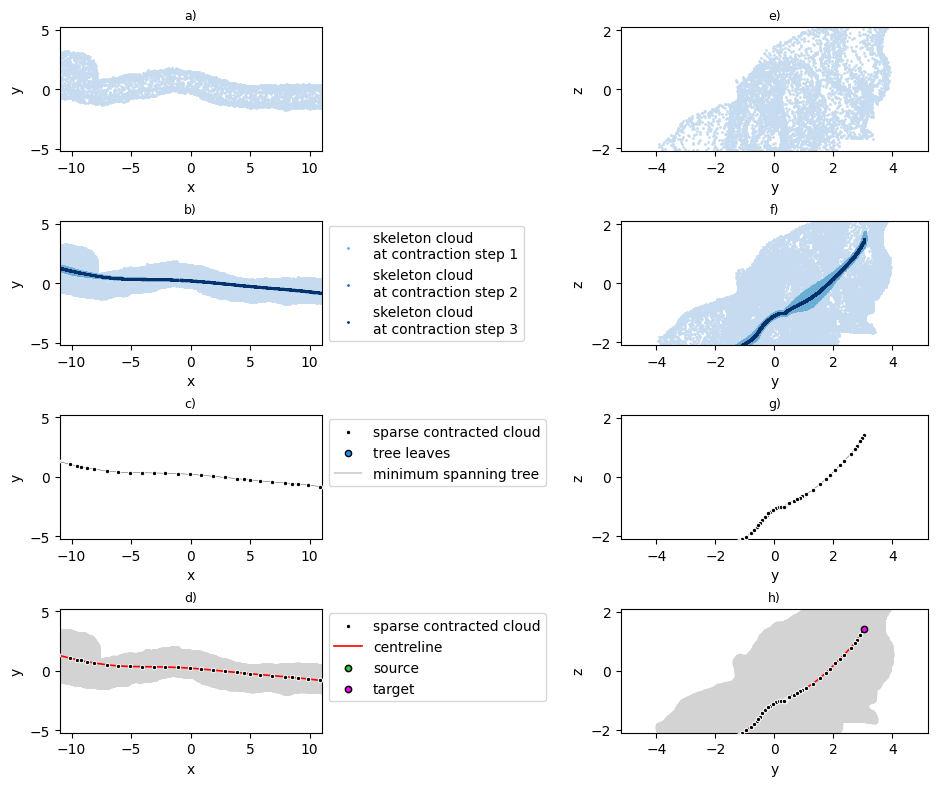

In [17]:
colors = Blues(np.linspace(0.25,1,4))
colors
skeleton_kwargs["color"] = colors[0]


gs = GridSpec(24, 40)

fig = plt.figure(figsize= (12, 10)) 

ax00 = fig.add_subplot(gs[0:4, 0:16])
# plot the first point cloud, before contraction. x y view 
ax00.scatter(*data.centroids[::75, [0, 1]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")

ax00.set_aspect("equal")
ax00.set_xlabel("x")
ax00.set_ylabel("y")


ax01 = fig.add_subplot(gs[0:4, 26:])
# plot the first point cloud, before contraction. y z view 
ax01.scatter(*data.centroids[::75, [1, 2]].T, **skeleton_kwargs, label = "skeleton cloud\nbefore contraction")
ax01.set_aspect("equal")
ax01.set_xlabel("y")
ax01.set_ylabel("z")

ax11 = fig.add_subplot(gs[6:10, 0:16])
ax12 = fig.add_subplot(gs[6:10, 26:])


k = 0
ax11.scatter(*data.centroids[::20, [0, 1]].T, **skeleton_kwargs)
ax12.scatter(*data.centroids[::20, [1, 2]].T, **skeleton_kwargs)

for cloud, color in zip(skeleton_clouds, colors[1:]):
    k+=1
    if k < 4:
        the_pcd = np.asarray(cloud.points)
        skeleton_kwargs["color"] = color
        ax11.scatter(*the_pcd[:, [0, 1]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")
        ax12.scatter(*the_pcd[:, [1, 2]].T, **skeleton_kwargs, label =f"skeleton cloud\nat contraction step {k}")


ax11.set_aspect("equal")
ax11.set_xlabel("x")
ax11.set_ylabel("y")     
ax12.set_aspect("equal")
ax12.set_xlabel("y")
ax12.set_ylabel("z")
ax11.legend(loc="upper left", bbox_to_anchor=(1., 1.02))




## mesh and the LBC centreline. 
ax31 = fig.add_subplot(gs[12:16, 0:16])
ax32 = fig.add_subplot(gs[12:16, 26:])

# plot the sparse cloud
ax31.scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, **node_kwargs, label = "sparse contracted cloud")
ax31.set_aspect("equal")

ax31.scatter(*out_LBC["sparse_cloud"][degree==1][:, [0, 1]].T, edgecolor="k", s=20, color="dodgerblue", zorder=121, label ="tree leaves")
p, q = edge_index.T[0]
ax31.plot(*out_LBC["sparse_cloud"][[p, q]][:, [0, 1]].T, color ="k", lw = 0.25, label ="minimum spanning tree")

for p, q in edge_index.T:
    ax31.plot(*out_LBC["sparse_cloud"][[p,q]][:, [0, 1]].T, color ="k", lw = 0.25)
    ax32.plot(*out_LBC["sparse_cloud"][[p,q]][:, [1, 2]].T, color ="k", lw = 0.25)
# plot the LBC estimate of the centreline
ax31.set_xlabel("x")
ax31.set_ylabel("y")
ax31.legend(loc="upper left", bbox_to_anchor=(1, 1.02))


# plot the sparse cloud
ax32.scatter(*out_LBC["sparse_cloud"][:, [1, 2]].T, **node_kwargs, label = "sparse contracted cloud")
ax32.set_aspect("equal")

ax32.set_xlabel("y")
ax32.set_ylabel("z")

## mesh and the LBC centreline. 
ax41 = fig.add_subplot(gs[18:22, 0:16])
ax42 = fig.add_subplot(gs[18:22, 26::])
# plot the sparse cloud
ax41.scatter(*out_LBC["sparse_cloud"][:, [0, 1]].T, **node_kwargs, label = "sparse contracted cloud")
# plot the LBC estimate of the centreline 
ax41.plot(*LBC_ct[:, [0, 1]].T, **ct_kwargs, label = "centreline")
# plot the start and end point
ax41.scatter(*P1[[0, 1]],**start_kwargs)
ax41.scatter(*P2[[0, 1]],**end_kwargs)
# plot the mesh 
ax41.scatter(*data.centroids[::5, [0, 1]].T, **mesh_kwargs)
ax41.set_aspect("equal")
ax41.legend(loc="upper left", bbox_to_anchor=(1, 1.02))
ax41.set_xlabel("x")
ax41.set_ylabel("y")


# plot the sparse cloud
ax42.scatter(*out_LBC["sparse_cloud"][:, [1, 2]].T, **node_kwargs, label = "sparse contracted cloud")
# plot the LBC estimate of the centreline 
ax42.plot(*LBC_ct[:, [1, 2]].T, **ct_kwargs, label = "centreline")
# plot the start and end point
ax42.scatter(*P1[[1, 2]],**start_kwargs)
ax42.scatter(*P2[[1, 2]],**end_kwargs)
# plot the mesh 
ax42.scatter(*data.centroids[::5, [1, 2]].T, **mesh_kwargs)
ax42.set_aspect("equal")

ax42.set_xlabel("y")
ax42.set_ylabel("z")

for ax in (ax00,ax11,ax31,ax41):
    ax.set_ylim(-5.2, 5.2)
    ax.set_xlim(-11, 11)

for ax in (ax01,ax12,ax32,ax42):
    ax.set_xlim(-5.2, 5.2)
    ax.set_ylim(-2.1, 2.1)

ax00.set_title("a)", fontdict=dict(fontsize=9))
ax11.set_title("b)", fontdict=dict(fontsize=9))
ax31.set_title("c)", fontdict=dict(fontsize=9))
ax41.set_title("d)", fontdict=dict(fontsize=9))
ax01.set_title("e)", fontdict=dict(fontsize=9))
ax12.set_title("f)", fontdict=dict(fontsize=9))
ax32.set_title("g)", fontdict=dict(fontsize=9))
ax42.set_title("h)", fontdict=dict(fontsize=9))

plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_lbc_contraction_steps.png", dpi = 300)
plt.savefig(f"./temp/{ID}_{CONDUIT_NAME}/lbc/{CONDUIT_NAME}_lbc_contraction_steps.pdf")
plt.show()